# What the Laplace–Beltrami spectrum determines (Phase 3, step 2)

**Question.** Which geometric quantities can be read from a lesion's spectrum, which cannot, and how much of that survives on real meshes? Do higher modes or lighter smoothing, untested in [`lb-invariance.ipynb`](lb-invariance.ipynb), add signal beyond size?

Results are stated in the cells below each section and summarised in Section 6. How to rerun: [`docs/reproductions/lb-spectrum-content.md`](../docs/reproductions/lb-spectrum-content.md).

## 1. Theory

**Weyl's law** [Weyl 1912]. For a closed surface, $N(\lambda)=\#\{k:\lambda_k\le\lambda\}\sim\frac{\text{Area}}{4\pi}\lambda$. So the spectrum determines area: $4\pi k/(\lambda_k\text{Area})\to1$.

**Heat trace** [McKean and Singer 1967]. As $t\to0$,
$$Z(t)=\sum_k e^{-\lambda_k t}=\frac{\text{Area}}{4\pi t}+\frac{\chi}{6}+\frac{t}{60\pi}\int_S K^2\,dA+O(t^2).$$
So the spectrum determines area, the Euler number $\chi$ (hence the genus) and $\int K^2$. Unit-sphere check: $Z=1/t+1/3+t/15$ matches $\text{Area}=4\pi$, $\chi=2$, $\int K^2=4\pi$. With $\tau=t/\text{Area}$ the coefficients are scale-free: $c_0=1$, $\chi$, and $c_2=\text{Area}\int K^2/(60\pi)$.

**Limits** [Kac 1966]. Spectra do not determine shape:

1. The isometric dent in `lb-invariance.ipynb` has one spectrum and two volumes, so **volume is not spectral**.
2. Sunada pairs are not even isometric. Section 2 builds one.

Consequently, any size signal must come from area: after $\lambda\cdot$Area normalisation, the spectrum cannot recover size at all in the continuous theory, because scaling leaves it fixed.

## 2. Verification

Tests in `test/utils_tests/features_tests/test_signature.py`: the heat fit on the analytic sphere spectrum, on fine sphere and torus meshes, and the Sunada pair. The pair glues 7 identical triangles in two patterns taken from the actions of $GL(3,2)$ on the points and lines of the Fano plane, doubled to close the surface.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, trimesh
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from abus_classification.features.shape_descriptor.shape_descriptors import compute_eigendecomposition, heat_trace_coefficients, lb_spectrum
from test.utils_tests.features_tests.test_signature import SUNADA_LINES, SUNADA_POINTS, sunada_surface

d = np.load("../results/lb-spectrum-content/spectra.npz")
lam, area, volume, euler, curvature_sq = d["lam"], d["area"], d["volume"], d["euler"], d["curvature_sq"]
na = lam * area[..., None]
SURFACES = ["Staircase", "Smoothed 0.4 mm", "Smoothed 0.8 mm"]
INK, GRID = "#52514e", "#e4e3df"; COLORS = ["#eb6834", "#1baf7a", "#2a78d6"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})

(L1, M1), (L2, M2) = sunada_surface(SUNADA_POINTS), sunada_surface(SUNADA_LINES)
l1, p1 = compute_eigendecomposition(L1, M1, 40); l2, p2 = compute_eigendecomposition(L2, M2, 40)
t = 1 / l1[3]; h1, h2 = (np.sort((np.exp(-l * t) * p ** 2).sum(1)) for l, p in ((l1, p1), (l2, p2)))
print(f"Sunada pair: largest relative eigenvalue gap {np.abs(l1[1:] / l2[1:] - 1).max():.1e}; largest gap in the sorted heat kernel diagonal {np.abs(h1 - h2).max() / h1.mean():.3f}")
for name, m in (("Sphere", trimesh.creation.icosphere(subdivisions=6)), ("Torus", trimesh.creation.torus(major_radius=2, minor_radius=1, major_sections=256, minor_sections=128))):
    c0, chi, _ = heat_trace_coefficients(lb_spectrum(m, 100, False), m.area)
    print(f"{name}: {len(m.vertices)} vertices, true chi {m.euler_number}, fitted chi {chi:.2f}, fitted area ratio {c0:.3f}")

Sunada pair: largest relative eigenvalue gap 1.6e-14; largest gap in the sorted heat kernel diagonal 0.041


Sphere: 40962 vertices, true chi 2, fitted chi 1.98, fitted area ratio 1.001


Torus: 32768 vertices, true chi 0, fitted chi -0.07, fitted area ratio 1.002


## 3. Implementation details

| Choice | Ours | Why |
|---|---|---|
| Grid | Isotropic 0.4 mm, no rotation | Fixed motion; rigid effects are covered in the previous notebook |
| Surfaces | Staircase; Gaussian $\sigma$ 0.4 and 0.8 mm | Tests the lighter smoothing left open |
| Modes | Up to 300, fewer when a mesh is too small (4 lesions on the 0.8 mm surface) | Weyl needs many modes |
| Heat window | $\tau$ from $8/(\lambda_{100}\text{Area})$ to 0.02, first 100 eigenvalues | Keeps the truncated tail negligible; chosen on sphere and torus meshes, not on lesions |
| Discrete $\int K^2$ | Sum of angle defect² / vertex area | Standard, but mesh-dependent on rough surfaces |
| Mesh | Largest piece | Each extra piece adds a zero mode |
| Labels | Train+Validation (130) only | Test stays clean |

## 4. Recovery on lesions

What the spectrum reports for three real lesions, on the surfaces it was computed from. Fitted area and χ use only the eigenvalues. Staircase surfaces have many handles, which is what the χ fit has to detect.

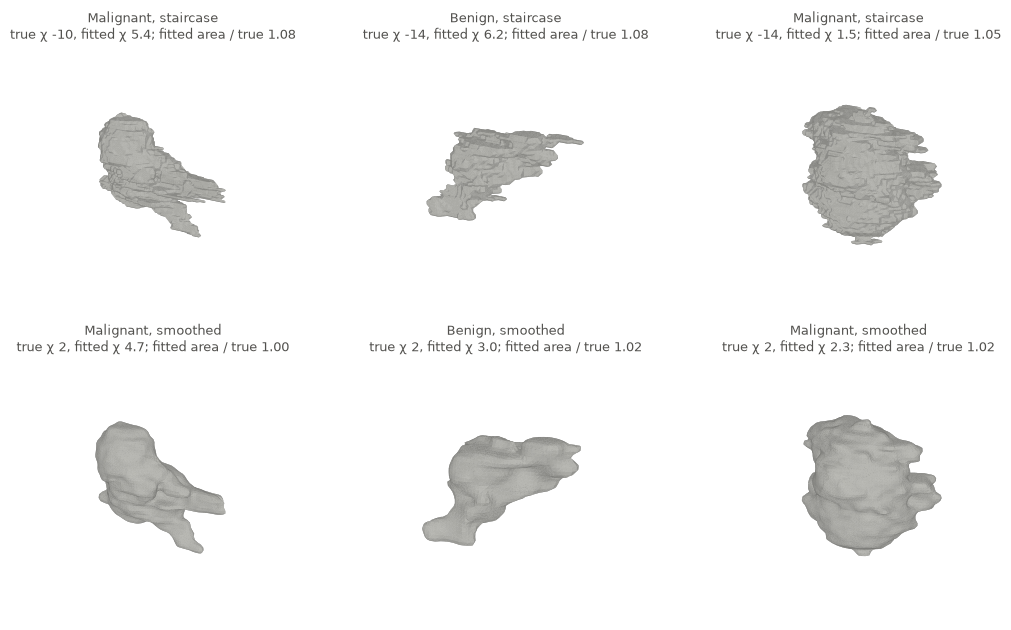

In [2]:
from abus_classification.utils.mesh import draw_mesh
samples = np.load("../results/lb-spectrum-content/sample_meshes.npz"); picks = ["malignant_q50", "benign_q50", "malignant_q75"]
fig = plt.figure(figsize=(11, 6.4))
for row, surface in enumerate(("staircase", "smoothed")):
    for col, name in enumerate(picks):
        m = trimesh.Trimesh(samples[f"{name}_{surface}_vertices"].astype(float), samples[f"{name}_{surface}_faces"], process=False)
        c0, chi, _ = heat_trace_coefficients(lb_spectrum(m, 100, False), m.area)
        ax = fig.add_subplot(2, 3, row * 3 + col + 1, projection="3d"); draw_mesh(ax, m)
        ax.set_title(f"{name.split('_')[0].capitalize()}, {surface}\ntrue χ {m.euler_number}, fitted χ {chi:.1f}; fitted area / true {c0:.2f}", fontsize=9, color=INK)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-recovery.png", dpi=130); plt.show()

,k=10,k=20,k=50,k=100,k=200,k=300
Staircase,1.188000,1.113000,1.067000,1.053000,1.048000,1.054000
Smoothed 0.4 mm,1.146000,1.078000,1.047000,1.041000,1.050000,1.070000
Smoothed 0.8 mm,1.117000,1.056000,1.036000,1.036000,1.059000,1.088000


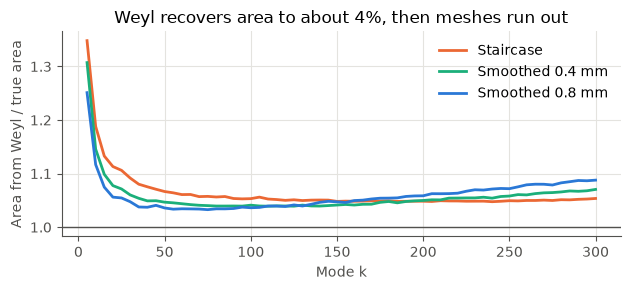

In [3]:
ks = [10, 20, 50, 100, 200, 300]; rows = {}
for s, name in enumerate(SURFACES):
    rows[name] = [np.nanmedian(4 * np.pi * k / na[:, s, k - 1]) for k in ks]
display(pd.DataFrame(rows, index=[f"k={k}" for k in ks]).T.round(3).style.set_caption("Weyl: median 4πk / (λ·Area); 1 is exact"))
fig, ax = plt.subplots(figsize=(6.5, 3)); k = np.arange(5, 301, 5)
for s, name in enumerate(SURFACES):
    y = [np.nanmedian(4 * np.pi * i / na[:, s, i - 1]) for i in k]; ax.plot(k, y, lw=2, color=COLORS[s], label=name)
ax.axhline(1, color=INK, lw=1); ax.set(xlabel="Mode k", ylabel="Area from Weyl / true area", title="Weyl recovers area to about 4%, then meshes run out"); ax.legend(frameon=False); plt.tight_layout()
plt.savefig("../docs/assets/lb-weyl.png", dpi=160); plt.show()

In [4]:
fits = np.array([[heat_trace_coefficients(l[np.isfinite(l)][:100], a) for l, a in zip(lam[:, s], area[:, s])] for s in range(3)]).transpose(1, 0, 2)
rows = {}
for s, name in enumerate(SURFACES):
    c2_true = area[:, s] * curvature_sq[:, s] / (60 * np.pi); g0 = euler[:, s] == 2
    rows[name] = {"Share genus 0": g0.mean(), "Median true χ": np.median(euler[:, s]), "Median fitted area ratio": np.median(fits[:, s, 0]),
                  "Fitted χ, genus 0, median": np.median(fits[g0, s, 1]), "Fitted χ, genus 0, 5th pct": np.percentile(fits[g0, s, 1], 5), "Fitted χ, genus 0, 95th pct": np.percentile(fits[g0, s, 1], 95),
                  "Mean |fitted − true χ|": np.abs(fits[:, s, 1] - euler[:, s]).mean(), "Spearman, fitted χ and volume": spearmanr(fits[:, s, 1], volume[:, s])[0],
                  "Spearman, fitted c2 and discrete c2": spearmanr(fits[:, s, 2], c2_true)[0], "Spearman, discrete c2 and volume": spearmanr(c2_true, volume[:, s])[0]}
pd.DataFrame(rows).round(3)

,Staircase,Smoothed 0.4 mm,Smoothed 0.8 mm
Share genus 0,0.125,0.885,0.975
Median true χ,-6.000,2.000,2.000
Median fitted area ratio,1.048,1.023,1.012
"Fitted χ, genus 0, median",2.657,2.633,2.146
"Fitted χ, genus 0, 5th pct",0.359,0.303,-0.573
"Fitted χ, genus 0, 95th pct",5.258,6.213,4.797
Mean |fitted − true χ|,15.488,1.997,1.411
"Spearman, fitted χ and volume",-0.164,0.477,0.790
"Spearman, fitted c2 and discrete c2",0.020,-0.609,-0.823
"Spearman, discrete c2 and volume",0.971,0.834,0.845


**Reading this.** Area is recoverable. The Euler number works on fine clean meshes (Section 2), but per lesion the fit is too noisy to count handles, and on the staircase surfaces it misses them entirely. Fitted $c_2$ does not track the discrete $\int K^2$, and the discrete value itself follows volume, so neither is a usable curvature measure yet. On smoothed surfaces the fitted χ follows volume: a size leak, since scale should not affect it.

## 5. Signal beyond size

Train+Validation only. Five-fold logistic regression, repeated 20 times. "After volume" regresses log volume out of each feature first. Two controls: sphericity, a surface measure, and Tan's coronal spiculation, which earlier work here found is not a size proxy. If spiculation keeps its signal after volume is removed, the check has the power to see one.

In [5]:
tv = ~d["test"]; y = d["y"][tv]
def cv(X):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    return np.mean([roc_auc_score(y, cross_val_predict(m, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=s), method="decision_function")) for s in range(20)])
def after_volume(X, v): return X - LinearRegression().fit(v, X).predict(v)
rows, leak = {}, {}
for s, name in enumerate(SURFACES):
    v = np.log(volume[tv, s])[:, None]; row = {"Volume": cv(v)}
    for K in (20, 50, 100):
        X = np.log(na[tv, s, 1:K + 1]); row[f"λ·Area, k≤{K}"] = cv(X); row[f"+ volume, k≤{K}"] = cv(np.c_[v, X]); row[f"After volume, k≤{K}"] = cv(after_volume(X, v))
    sph = np.log(area[tv, s] ** 3 / volume[tv, s] ** 2)[:, None]
    row["Sphericity (A³/V²)"] = cv(sph); row["Control: sphericity after volume"] = cv(after_volume(sph, v))
    rows[name] = row
    leak[name] = {f"k={k}": spearmanr(na[:, s, k], volume[:, s])[0] for k in (1, 20, 50, 100, 200)}
tan = pd.read_csv("../results/lb-spectrum-content/tan_control.csv")[["SPmean", "SP90", "SP75"]].values[tv]
v = np.log(volume[tv, 2])[:, None]
print(f"Control, Tan spiculation (from image gradients): {cv(tan):.3f}; after volume {cv(after_volume(tan, v)):.3f}")
display(pd.DataFrame(rows).round(3).style.format(precision=3).set_caption("Cross-validated AUC"))
pd.DataFrame(leak).T.round(3).style.format(precision=3).set_caption("Spearman of λ·Area with volume; 0 is expected in theory")

Control, Tan spiculation (from image gradients): 0.788; after volume 0.688


,Staircase,Smoothed 0.4 mm,Smoothed 0.8 mm
Volume,0.709,0.709,0.710
"λ·Area, k≤20",0.564,0.543,0.601
"+ volume, k≤20",0.649,0.635,0.657
"After volume, k≤20",0.482,0.471,0.483
"λ·Area, k≤50",0.620,0.485,0.553
"+ volume, k≤50",0.654,0.566,0.573
"After volume, k≤50",0.491,0.404,0.392
"λ·Area, k≤100",0.646,0.541,0.531
"+ volume, k≤100",0.649,0.563,0.550
"After volume, k≤100",0.461,0.399,0.374


,k=1,k=20,k=50,k=100,k=200
Staircase,0.052,-0.373,-0.427,-0.053,0.588
Smoothed 0.4 mm,-0.035,-0.290,0.255,0.716,0.958
Smoothed 0.8 mm,-0.095,0.155,0.746,0.948,nan


## 6. Conclusions

- **Determined and usable:** area, to about 4% from modes around $k=50$–100.
- **Determined in theory, not usable per lesion yet:** $\chi$ and $\int K^2$.
- **Not determined at all:** volume, and in general shape (the dent and the Sunada pair).
- **Normalisation is not enough.** $\lambda_k\cdot$Area is scale-free on paper, but at fixed voxel size and smoothing width, high modes depend on lesion size. Small lesions have fewer vertices and are smoothed more relative to their size. Size-matched smoothing and meshes are needed for a true scale-free comparison.
- **In a linear reading, the spectrum adds nothing to volume here.** After volume is removed, AUC stays at or below 0.49 on every surface and mode count, and adding the modes to volume lowers its 0.71. Spiculation keeps 0.69 under the same check, so the check can see signal. Spiculation uses image gradients, not only the surface. Sphericity also falls to about chance, so no surface measure tried here has survived this check yet.

## 7. Protocol

All 200 lesions for recovery; labels on the 130 Train+Validation lesions only. Malignant is positive. CPU only, no Kaggle kernel. Stored results: `results/lb-spectrum-content/spectra.npz`. The challenge benchmark does not apply: nothing here produces predictions.

## 8. Open issues

- **Scale-matched meshing.** Remesh every lesion to one vertex count, and smooth relative to its size, then repeat Section 5. This is the fairest remaining test.
- **Non-linear readings.** Only logistic regression on log eigenvalues was tried.
- **Mask quality.** Eigenvalues from ground-truth masks at 0.476 mm slice spacing inherit annotation noise. The stability step should measure it.
- **Hersch's bound.** The next roadmap step. All genus-0 smoothed surfaces here satisfy it, with $\lambda_1\text{Area}/8\pi$ up to 0.91.